# Customer Churn Prediction

## 1. Business Problem

Customer churn refers to customers discontinuing a company's service.

For a subscription-based telecom company, retaining existing customers is often important because losing customers reduces recurring revenue and increases the need to acquire new customers.

The goal of this project is to:

1. Understand the characteristics associated with customer churn.
2. Explore patterns in customer demographics, services, contracts, and billing.
3. Build machine-learning models to predict whether a customer is likely to churn.
4. Identify the factors that contribute most to churn.
5. Translate the model results into actionable customer-retention insights.

### Target Variable

The target variable is `Churn`:

- `Yes` → customer churned
- `No` → customer did not churn

In [91]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [92]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [93]:
df.shape

(7043, 21)

In [94]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [95]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors = "coerce"
)

In [96]:
df["TotalCharges"].isna().sum()

np.int64(11)

In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [98]:
df[df["TotalCharges"].isna()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [99]:
df[df["TotalCharges"].isna()]["tenure"].value_counts()

tenure
0    11
Name: count, dtype: int64

In [100]:
df.loc[df["TotalCharges"].isna(), "TotalCharges"] = 0

In [101]:
df["TotalCharges"].isna().sum()

np.int64(0)

In [102]:
df["TotalCharges"].fillna(df["TotalCharges"].mean())

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

In [103]:
df.duplicated().sum()

np.int64(0)

In [104]:
df["customerID"].duplicated().sum()

np.int64(0)

In [105]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [106]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [107]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

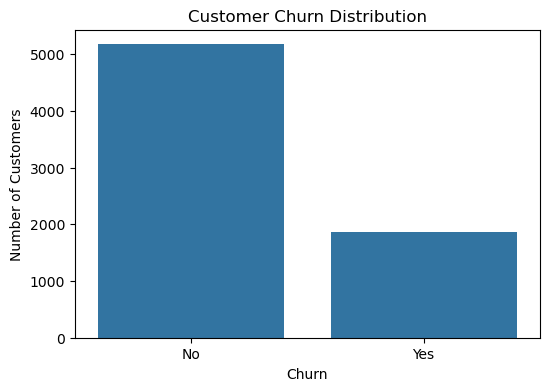

In [108]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

EDA

In [109]:
def churn_rate(variable):
    return (
        pd.crosstab(
            df[variable],
            df["Churn"],
            normalize="index"
        ) * 100
    ).round(2)

In [110]:
churn_rate("Contract")

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [111]:
churn_rate("InternetService")

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [112]:
churn_rate("SeniorCitizen")

Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


Reusable churn rate function

In [113]:
def churn_rate(variable):
    return (
        pd.crosstab(
            df[variable],
            df["Churn"],
            normalize="index"
        ) * 100
    ).round(2)

Analyze customer demographics

In [114]:
demographic_vars = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

for variable in demographic_vars:
    print(f"\nChurn rate by {variable}")
    print(churn_rate(variable))


Churn rate by gender
Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16

Churn rate by SeniorCitizen
Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68

Churn rate by Partner
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66

Churn rate by Dependents
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45


In [115]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({
    0: "No",
    1: "Yes"
})

Visualize demographic churn rate

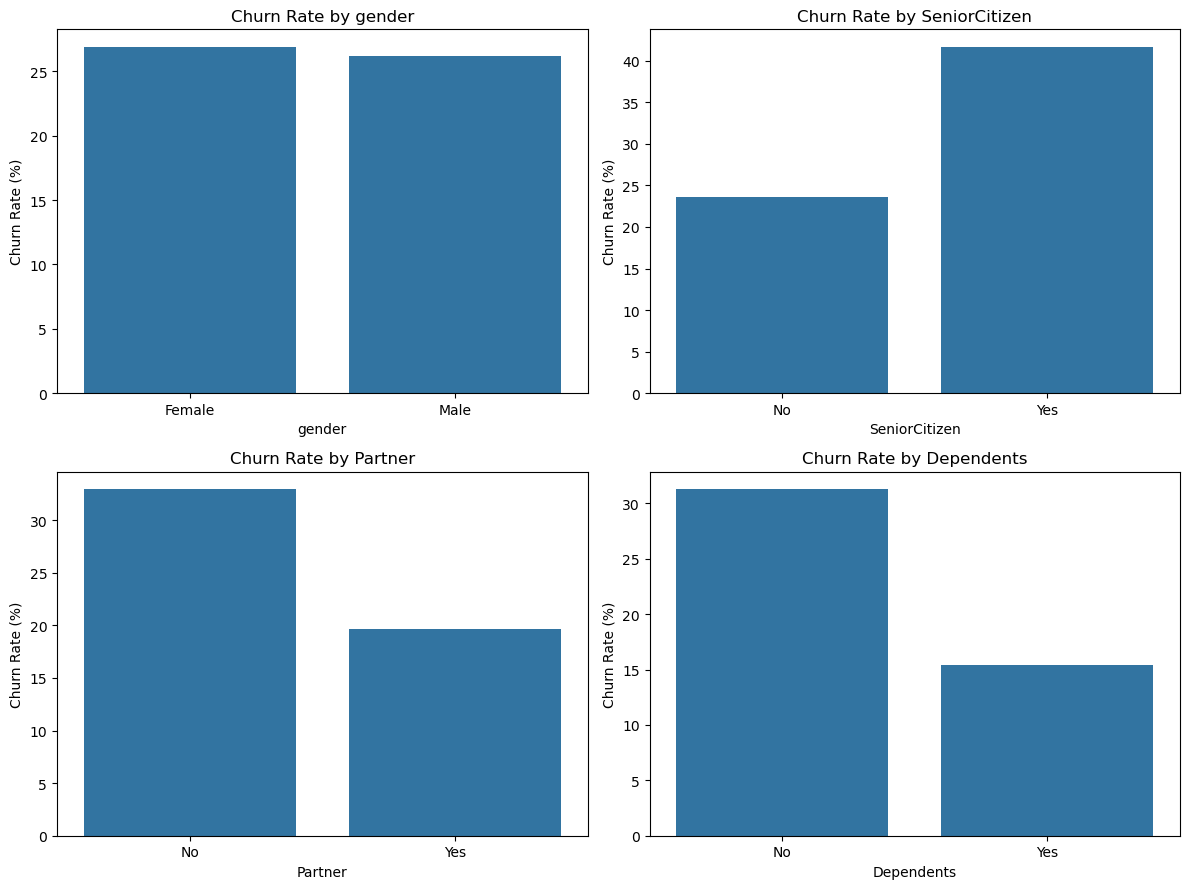

In [116]:
demographic_vars = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for variable, ax in zip(demographic_vars, axes.flatten()):
    rates = df.groupby(variable, observed=True)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100
    )

    sns.barplot(x=rates.index, y=rates.values, ax=ax)

    ax.set_title(f"Churn Rate by {variable}")
    ax.set_xlabel(variable)
    ax.set_ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

Churn rate by contract

In [117]:
churn_rate("Contract")

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


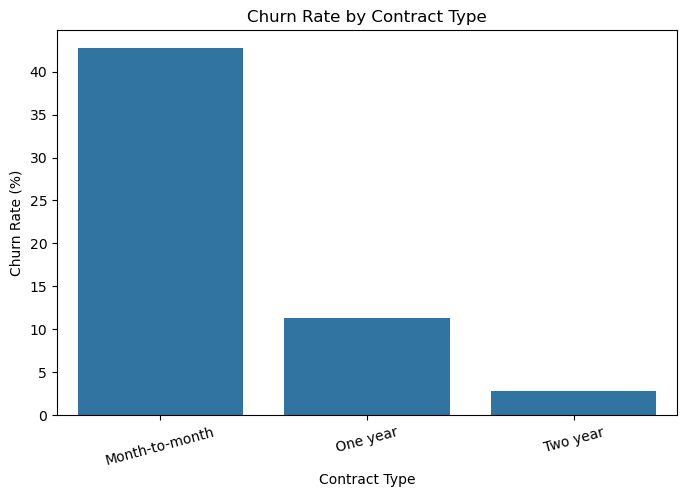

In [172]:
contract_rates = (
    df.groupby("Contract", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_rates.index,
    y=contract_rates.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

plt.savefig(r"images\churn_by_contract.png",
            dpi=300, bbox_inches="tight")
plt.show()

Analyze tenure

In [119]:
df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

,count,mean,median,std,min,max
Churn,,,,,,
No,5174,37.57,38.0,24.11,0,72
Yes,1869,17.98,10.0,19.53,1,72


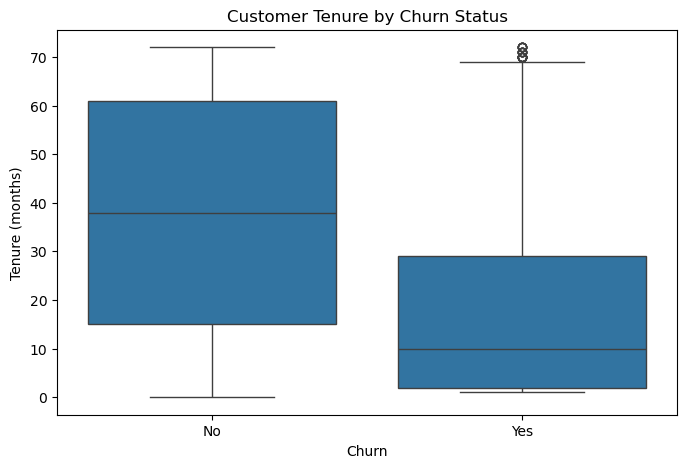

In [181]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.show()

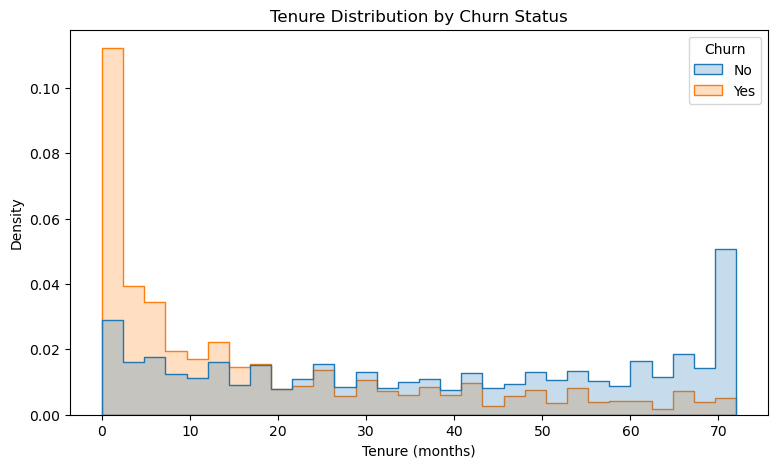

In [174]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Tenure Distribution by Churn Status")
plt.xlabel("Tenure (months)")
plt.ylabel("Density")

plt.savefig(r"images\tenure_dist_by_churnstatus.png",
            dpi=300, bbox_inches="tight")
plt.show()

Service related variables 

In [122]:
service_vars = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for variable in service_vars:
    print(f"\nChurn rate by {variable}")
    print(churn_rate(variable))


Churn rate by PhoneService
Churn            No    Yes
PhoneService              
No            75.07  24.93
Yes           73.29  26.71

Churn rate by MultipleLines
Churn                No    Yes
MultipleLines                 
No                74.96  25.04
No phone service  75.07  24.93
Yes               71.39  28.61

Churn rate by InternetService
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

Churn rate by OnlineSecurity
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61

Churn rate by OnlineBackup
Churn                   No    Yes
OnlineBackup                     
No                   60.07  39.93
No internet service  92.60   7.40
Yes                  78.47  21.53

Churn rate by DeviceProtection
Churn                   No    Yes
DeviceProtection                 
N

Visualize service churn rates

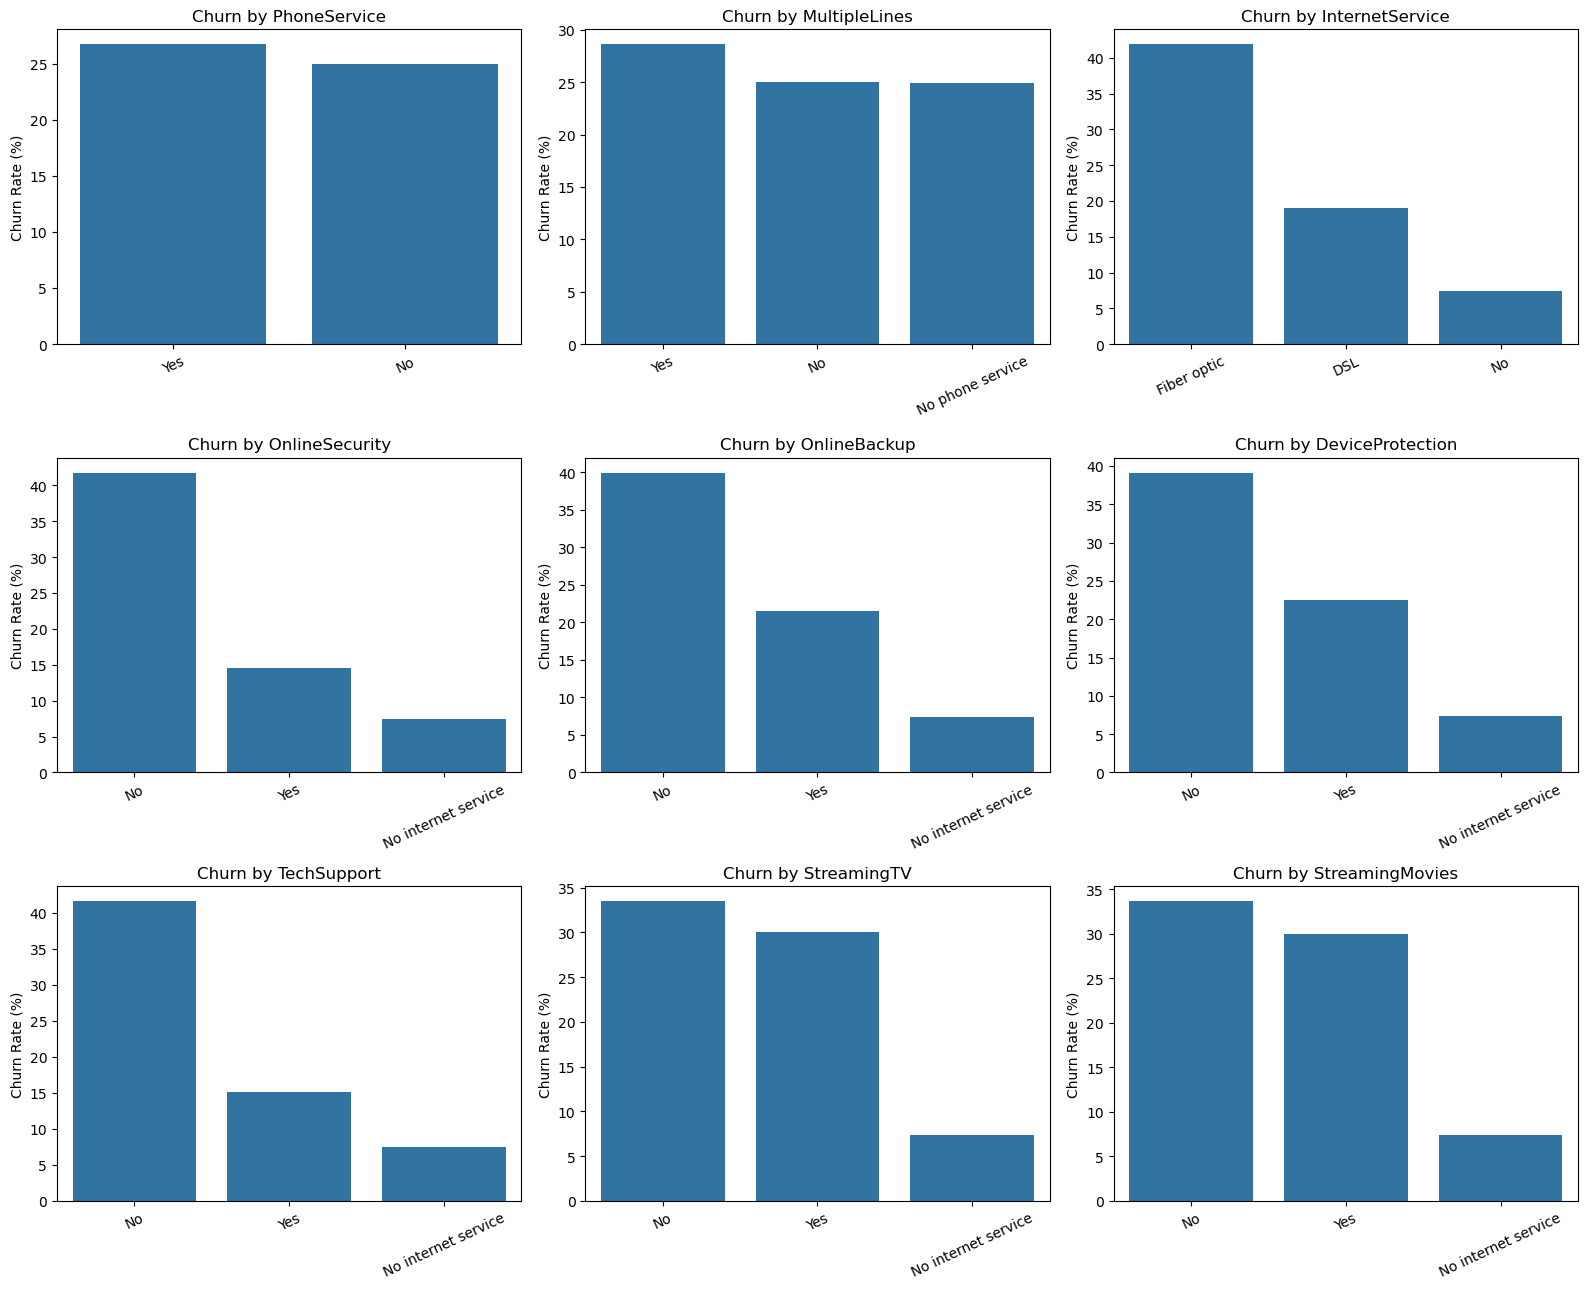

In [123]:
fig, axes = plt.subplots(3, 3, figsize=(16, 13))

for variable, ax in zip(service_vars, axes.flatten()):
    rates = (
        df.groupby(variable, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=rates.index,
        y=rates.values,
        ax=ax
    )

    ax.set_title(f"Churn by {variable}")
    ax.set_xlabel("")
    ax.set_ylabel("Churn Rate (%)")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

Billing and payment behaviour

In [124]:
churn_rate("PaymentMethod")

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


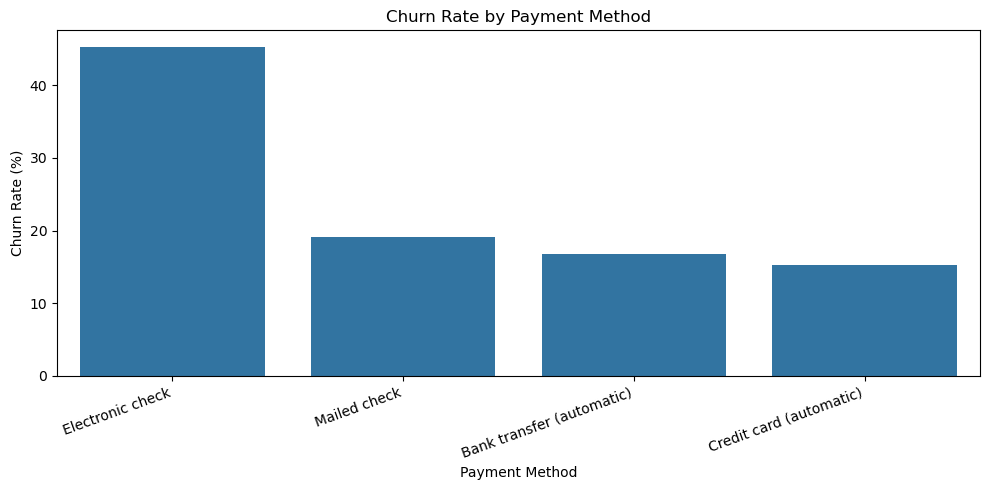

In [125]:
payment_rates = (
    df.groupby("PaymentMethod", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_rates.index,
    y=payment_rates.values
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

Monthly charges by churn status 

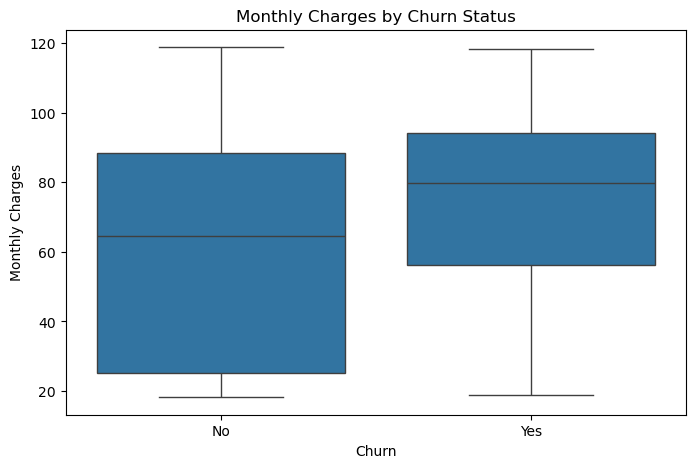

In [126]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

Total charges by churn status

In [127]:
df.groupby("Churn")["TotalCharges"].agg(
    ["mean", "median", "std", "min", "max"]
).round(2)

,mean,median,std,min,max
Churn,,,,,
No,2549.91,1679.52,2329.95,0.00,8672.45
Yes,1531.80,703.55,1890.82,18.85,8684.80


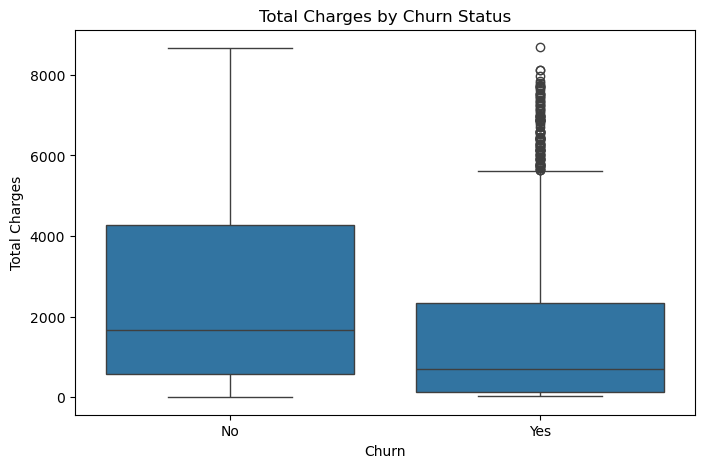

In [128]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

Numerical variables and correlations

In [129]:
numeric_vars = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numeric_vars].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


In [130]:
correlation_matrix = df[numeric_vars].corr()

correlation_matrix

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


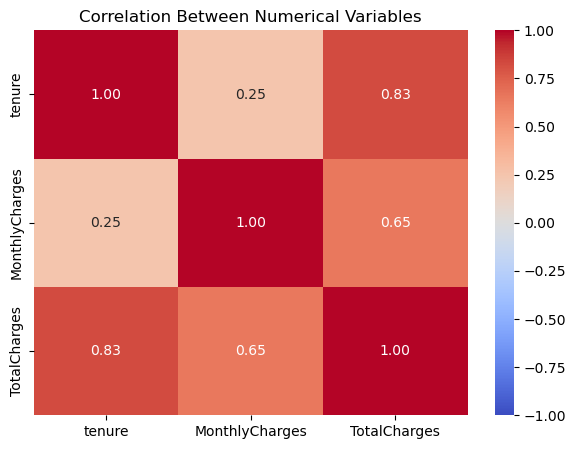

In [131]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Variables")
plt.show()


### Exploratory Data Analysis Summary

The exploratory data analysis (EDA) was conducted to understand the distribution of customer churn and investigate how churn patterns vary across customer characteristics, service subscriptions, contract types, and tenure.

### 1. Churn Distribution

The dataset contains approximately 73.46% customers who did not churn and 26.54% customers who churned. This indicates a moderate class imbalance, with the non-churn class representing the majority of observations. Therefore, accuracy alone may not adequately describe model performance, making precision, recall, F1-score, and ROC-AUC important evaluation metrics.

### 2. Customer Tenure

Customer tenure shows a strong association with churn. Customers with 0–12 months of tenure have an observed churn rate of approximately 47.44%, compared with 9.51% among customers with 49–72 months of tenure. This pattern suggests that newer customers may be a particularly important group for retention analysis.

### 3. Contract Type

Churn rates differ substantially by contract type. Month-to-month customers have an observed churn rate of 42.71%, while the rates for one-year and two-year contracts are 11.27% and 2.83%, respectively. Customers with longer-term contracts therefore exhibit considerably lower observed churn rates in this dataset.

### 4. Internet Service

Internet service type is also associated with differences in churn. Customers using fiber-optic internet have an observed churn rate of 41.89%, compared with 18.96% for DSL customers and 7.40% for customers without internet service. This pattern identifies internet service type as a potentially informative feature for predictive modeling.

### 5. Contract Type and Tenure Together

Examining contract type and tenure jointly reveals additional variation in churn patterns. Month-to-month customers show relatively high churn across tenure groups, particularly during the first 12 months, when the observed churn rate is approximately 51.35%. Customers with one-year and two-year contracts generally show lower observed churn rates.

However, the zero observed churn rates in the shortest-tenure groups for two-year contracts should be interpreted cautiously because these groups contain only 68 and 90 customers, respectively.

### Overall Findings

The EDA highlights customer tenure, contract type, and internet service as important variables associated with churn. These patterns provide a foundation for feature preparation and model development. However, the findings represent associations in the observed data and do not establish causal relationships.

Feature engineering and data preparation

define our prediction target

In [132]:
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

y.value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

Separate features from the target

In [133]:
X = df.drop(columns=["Churn", "customerID"])

X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [134]:
print("Feature dimensions:", X.shape)
print("Target dimensions:", y.shape)

Feature dimensions: (7043, 19)
Target dimensions: (7043,)


Identify numerican and categorical features

In [135]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

print("Numerical features:", numeric_features)
print("\nNumber of categorical features:", len(categorical_features))
print(categorical_features)

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']

Number of categorical features: 16
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Splitting dataset

In [136]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [137]:
from sklearn.model_selection import train_test_split

X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_fit.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training subset: (4507, 19)
Validation set: (1127, 19)
Test set: (1409, 19)


Building the preprocessing pipeline

In [138]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

Numerican preprocessing

In [139]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

Categorical preprocessing

In [140]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

Combined transformation

In [141]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

BASELINE MODEL

In [142]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [143]:
#training baseline
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

In [144]:
#evaluating baseline
print("Baseline Accuracy:",
      round(accuracy_score(y_test, y_pred_baseline), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_baseline,
    zero_division=0
))

Baseline Accuracy: 0.7346

Classification Report:
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



TRAIN LOGISTIC REGRESSION

In [145]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [146]:
# make predictions
y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

Evaluate Logistic Regression

In [147]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, zero_division=0),
    "Recall": recall_score(y_test, y_pred_lr, zero_division=0),
    "F1": f1_score(y_test, y_pred_lr, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lr),
    "PR-AUC": average_precision_score(y_test, y_prob_lr)
}

pd.DataFrame([lr_results]).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.604,0.842,0.6337


In [148]:
#classfication report

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



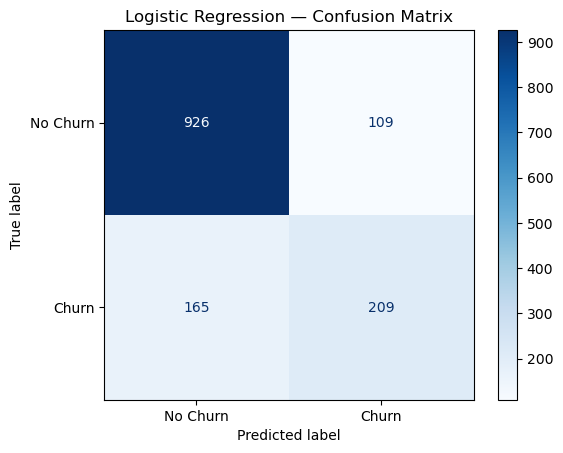

In [149]:
#plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Logistic Regression — Confusion Matrix")
plt.show()

In [150]:
# Model comparison
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    }

In [151]:
results = []

results.append(evaluate_model(
    "Logistic Regression",
    logistic_model,
    X_test,
    y_test
))

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.604,0.842,0.6337


TRAINING DECISION TREE

In [152]:
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        random_state=42,
        class_weight=None
    ))
])

tree_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [153]:
#Evaluate the tree
y_pred_tree = tree_model.predict(X_test)
y_prob_tree = tree_model.predict_proba(X_test)[:, 1]

tree_results = evaluate_model(
    "Decision Tree",
    tree_model,
    X_test,
    y_test
)

results.append(tree_results)

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8420,0.6337
1,Decision Tree,0.7984,0.6347,0.5668,0.5989,0.8276,0.6203


TRAINING RANDOM FOREST

In [154]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [155]:
#Evaluate Random Forest
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

rf_results = evaluate_model(
    "Random Forest",
    rf_model,
    X_test,
    y_test
)

results.append(rf_results)

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8420,0.6337
1,Decision Tree,0.7984,0.6347,0.5668,0.5989,0.8276,0.6203
2,Random Forest,0.7970,0.6517,0.5053,0.5693,0.8423,0.6529


In [156]:
from sklearn.base import clone

# Create independent copies of the existing pipelines
lr_val_model = clone(logistic_model)
dt_val_model = clone(tree_model)
rf_val_model = clone(rf_model)

# Fit each model using only the training subset
lr_val_model.fit(X_train_fit, y_train_fit)
dt_val_model.fit(X_train_fit, y_train_fit)
rf_val_model.fit(X_train_fit, y_train_fit)

print("All three models fitted successfully!")


All three models fitted successfully!


In [157]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

models = {
    "Logistic Regression": lr_val_model,
    "Decision Tree": dt_val_model,
    "Random Forest": rf_val_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "PR-AUC": average_precision_score(y_val, y_prob)
    })

validation_results = pd.DataFrame(results)

validation_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8163,0.6966,0.5452,0.6116,0.8482,0.6668
1,Decision Tree,0.7888,0.6667,0.4080,0.5062,0.8364,0.6312
2,Random Forest,0.8066,0.6919,0.4883,0.5725,0.8467,0.6558


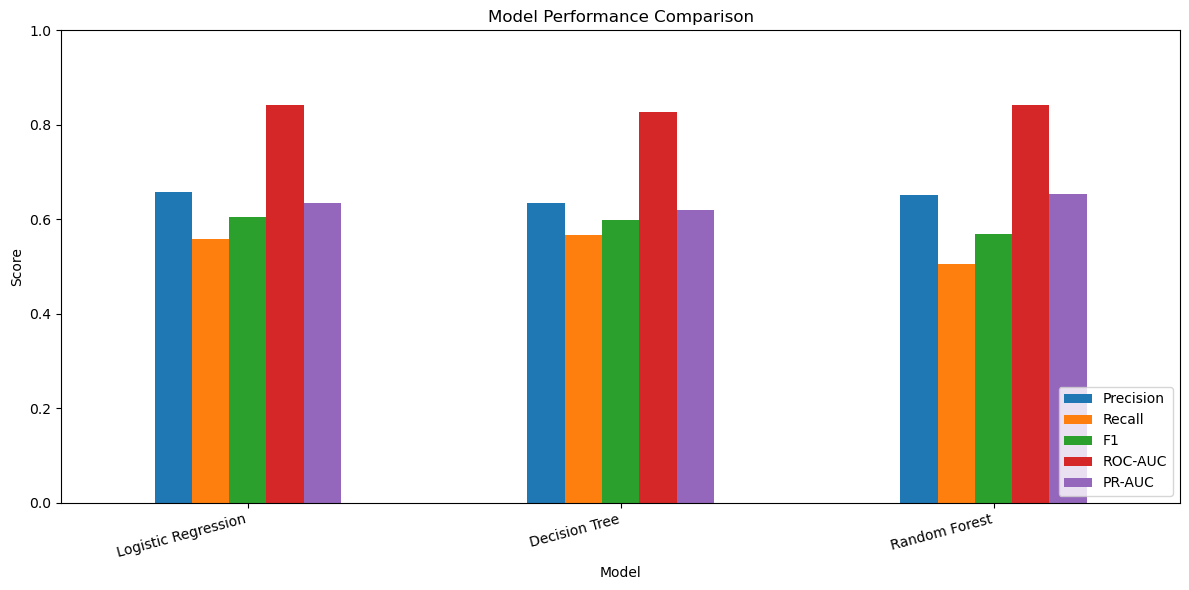

In [158]:
#Comparing the models visually
metrics_to_plot = [
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

results_plot = results_df.set_index("Model")[metrics_to_plot]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Model Comparison Results

Logistic Regression achieved the strongest validation performance across all six evaluated metrics, including ROC-AUC (0.8482) and average precision (PR-AUC: 0.6668). It was therefore selected as the provisional model for further evaluation.

The model achieved a recall of 0.5452 at the default classification threshold of 0.50, indicating that it identified approximately 54.5% of actual churners. Since identifying at-risk customers is an important objective, the classification threshold will be examined separately using validation data.

The validation results guide model and threshold selection. The held-out test set will be reserved for the final evaluation.

Can we improve churn detection without unnecessarily sacrificing precision?

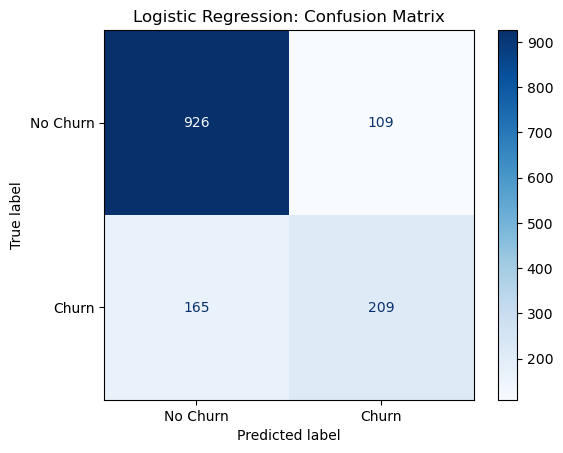

In [182]:
#examining confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Logistic Regression: Confusion Matrix")
plt.show()

In [160]:
#Validation set
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create a separate copy of the Logistic Regression pipeline
validation_model = clone(logistic_model)

# Train using only the smaller training set
validation_model.fit(X_train_fit, y_train_fit)

# Get churn probabilities for the validation set
y_prob_val = validation_model.predict_proba(X_val)[:, 1]

In [161]:
#Compare thresholds on validation dataset
threshold_results_val = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    y_pred_val = (y_prob_val >= threshold).astype(int)

    threshold_results_val.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_pred_val, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred_val, zero_division=0
        ),
        "F1": f1_score(
            y_val, y_pred_val, zero_division=0
        )
    })

validation_threshold_df = pd.DataFrame(threshold_results_val)

validation_threshold_df.round(4)

,Threshold,Precision,Recall,F1
0,0.30,0.5433,0.7559,0.6322
1,0.35,0.5792,0.7090,0.6376
2,0.40,0.6173,0.6689,0.6421
3,0.45,0.6606,0.6054,0.6318
4,0.50,0.6966,0.5452,0.6116
5,0.55,0.7317,0.5017,0.5952
6,0.60,0.7285,0.3679,0.4889


In [162]:
# Use the selected threshold
selected_threshold = 0.35

# Refit Logistic Regression on the full training set
logistic_model.fit(X_train, y_train)

# Predict churn probabilities for the test set
y_prob_test = logistic_model.predict_proba(X_test)[:, 1]

# Convert probabilities into predictions using threshold 0.35
y_pred_final = (y_prob_test >= selected_threshold).astype(int)

# Evaluate final performance
print("Selected threshold:", selected_threshold)

print(
    "Precision:",
    round(precision_score(y_test, y_pred_final), 4)
)

print(
    "Recall:",
    round(recall_score(y_test, y_pred_final), 4)
)

print(
    "F1-score:",
    round(f1_score(y_test, y_pred_final), 4)
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["No Churn", "Churn"]
    )
)

Selected threshold: 0.35
Precision: 0.5432
Recall: 0.7059
F1-score: 0.614

Classification report:
              precision    recall  f1-score   support

    No Churn       0.88      0.79      0.83      1035
       Churn       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



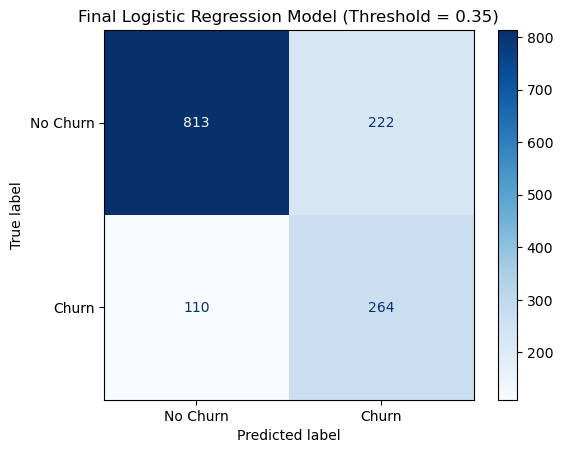

In [183]:
#visualizing final model
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Final Logistic Regression Model (Threshold = 0.35)")
plt.savefig(r"images\final_logistic_regression_model.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Final Model Evaluation

The Logistic Regression model was refitted on the full training set and evaluated on the held-out test set using a classification threshold of 0.35.

The model achieved a recall of 70.59%, meaning it identified approximately 71% of customers who actually churned. Its precision was 54.32%, indicating that approximately 54% of customers predicted to churn did so. The resulting F1-score was 0.6140.

The threshold of 0.35 prioritizes identifying more potential churners, at the cost of generating more false-positive predictions. This trade-off may be useful in a retention strategy where missing an at-risk customer is considered costly.

These results measure performance on the held-out test set and should not be used to tune the model further.

UNDERSTANDS WHAT DRIVES PREDICTED CHURN

In [164]:
#extract the model coefficients

import pandas as pd
import numpy as np

# Get the fitted preprocessing pipeline
preprocessor_fitted = logistic_model.named_steps["preprocessor"]

# Get the fitted Logistic Regression classifier
classifier_fitted = logistic_model.named_steps["classifier"]

# Recover feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Extract model coefficients
coefficients = classifier_fitted.coef_[0]

# Create a table
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

coef_df.head(20)

,Feature,Coefficient,Abs_Coefficient
0,num__tenure,-1.255202,1.255202
39,cat__Contract_Two year,-0.759402,0.759402
17,cat__InternetService_Fiber optic,0.648027,0.648027
16,cat__InternetService_DSL,-0.643642,0.643642
1,num__MonthlyCharges,-0.601168,0.601168
37,cat__Contract_Month-to-month,0.585998,0.585998
2,num__TotalCharges,0.532592,0.532592
40,cat__PaperlessBilling_No,-0.330735,0.330735
35,cat__StreamingMovies_No internet service,-0.292955,0.292955
32,cat__StreamingTV_No internet service,-0.292955,0.292955


In [165]:
#odds ratio

coef_df["Odds_Ratio"] = np.exp(coef_df["Coefficient"])

coef_df[
    ["Feature", "Coefficient", "Odds_Ratio"]
].head(20)

,Feature,Coefficient,Odds_Ratio
0,num__tenure,-1.255202,0.285018
39,cat__Contract_Two year,-0.759402,0.467946
17,cat__InternetService_Fiber optic,0.648027,1.911766
16,cat__InternetService_DSL,-0.643642,0.525375
1,num__MonthlyCharges,-0.601168,0.548171
37,cat__Contract_Month-to-month,0.585998,1.796784
2,num__TotalCharges,0.532592,1.703341
40,cat__PaperlessBilling_No,-0.330735,0.718396
35,cat__StreamingMovies_No internet service,-0.292955,0.746056
32,cat__StreamingTV_No internet service,-0.292955,0.746056


FEATURE IMPORTANCE

In [166]:
from sklearn.inspection import permutation_importance

# Measure how much each original feature contributes
perm_result = permutation_importance(
    validation_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance,Std
4,tenure,0.250119,0.018715
7,InternetService,0.111085,0.012306
14,Contract,0.058449,0.010246
18,TotalCharges,0.047128,0.014642
17,MonthlyCharges,0.039455,0.012560
13,StreamingMovies,0.025357,0.009620
12,StreamingTV,0.015301,0.010165
11,TechSupport,0.010900,0.006877
6,MultipleLines,0.010070,0.008377
16,PaymentMethod,0.009910,0.005561


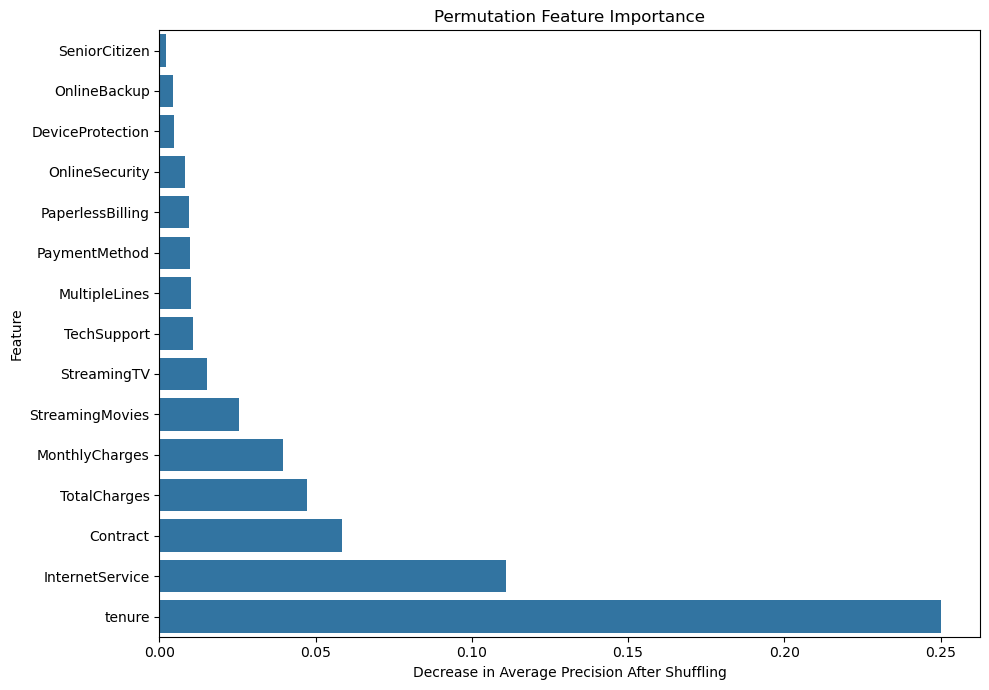

In [177]:
# visualizing full ranking
import matplotlib.pyplot as plt
import seaborn as sns

top_features = importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in Average Precision After Shuffling")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig(r"images\permutation_feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()

Comparing churn rates across most important features

In [168]:
# Churn rate by tenure group
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0–12 months",
        "13–24 months",
        "25–48 months",
        "49–72 months"
    ]
)

tenure_churn = churn_rate("TenureGroup")
display(tenure_churn)

# Churn rate by internet service
display(churn_rate("InternetService"))

# Churn rate by contract type
display(churn_rate("Contract"))

Churn,No,Yes
TenureGroup,,
0–12 months,52.56,47.44
13–24 months,71.29,28.71
25–48 months,79.61,20.39
49–72 months,90.49,9.51


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


## Key Business Insights

1. **Early customer retention:** Customers with 0–12 months of tenure have a churn rate of 47.44%, compared with 9.51% among customers with 49–72 months of tenure. This suggests that early-tenure customers deserve particular attention in retention planning.

2. **Internet-service segmentation:** Fiber optic customers have a churn rate of 41.89%, compared with 18.96% for DSL and 7.40% for customers without internet service. Further analysis is needed to understand the factors associated with this difference.

3. **Contract structure:** The churn rate is 42.71% for month-to-month customers, 11.27% for one-year contracts, and 2.83% for two-year contracts. Contract type is a promising dimension for customer segmentation and retention analysis.

4. **Model interpretation:** Permutation importance identifies tenure, internet service, and contract type as the three most useful individual features for the model's validation-set predictions, measured using average precision.

5. **Limitations:** These findings describe associations in the available dataset. They do not establish causation or guarantee that a proposed retention intervention will reduce churn.

In [169]:
# Churn rate by contract and tenure group
contract_tenure_churn = (
    pd.crosstab(
        [df["Contract"], df["TenureGroup"]],
        df["Churn"],
        normalize="index"
    ) * 100
).round(2)

display(contract_tenure_churn)

Churn                            No    Yes
Contract       TenureGroup                
Month-to-month 0–12 months    48.65  51.35
               13–24 months   62.28  37.72
               25–48 months   67.08  32.92
               49–72 months   73.98  26.02
One year       0–12 months    89.52  10.48
               13–24 months   91.88   8.12
               25–48 months   89.38  10.62
               49–72 months   87.07  12.93
Two year       0–12 months   100.00   0.00
               13–24 months  100.00   0.00
               25–48 months   97.81   2.19
               49–72 months   96.67   3.33

## Interaction Between Contract Type and Tenure

The cross-tabulation suggests that the association between tenure and churn varies by contract type. Month-to-month customers exhibit comparatively high churn across all tenure groups, with the observed rate declining from 51.35% among customers with 0–12 months of tenure to 26.02% among those with 49–72 months.

One-year contract customers exhibit substantially lower churn rates, ranging from 8.12% to 12.93%. Two-year contract customers have very low observed churn rates, although sample sizes should be examined before interpreting zero observed churn in some groups.

These findings suggest that tenure and contract type are useful dimensions for customer segmentation. However, the analysis is observational and does not establish that contract duration causes differences in churn.

In [170]:
#number of customers in each contract-tenure group
group_sizes = (
    df.groupby(
        ["Contract", "TenureGroup"],
        observed=False
        
    )
    .size()
    .unstack()
)

display(group_sizes)

TenureGroup,0–12 months,13–24 months,25–48 months,49–72 months
Contract,,,,
Month-to-month,1994,737,802,342
One year,124,197,518,634
Two year,68,90,274,1263


The cross-tabulation of contract type and tenure group shows that churn rates vary across customer segments. Month-to-month customers have relatively high churn rates across all tenure groups, particularly among customers with 0–12 months of tenure. In contrast, customers with one-year and two-year contracts generally exhibit much lower churn rates. The two-year contract groups with 0–12 and 13–24 months of tenure have zero observed churn, but these groups contain only 68 and 90 customers, respectively. Therefore, these results should be interpreted cautiously. Overall, the findings suggest an association between contract type, customer tenure, and churn, but they do not establish causation.

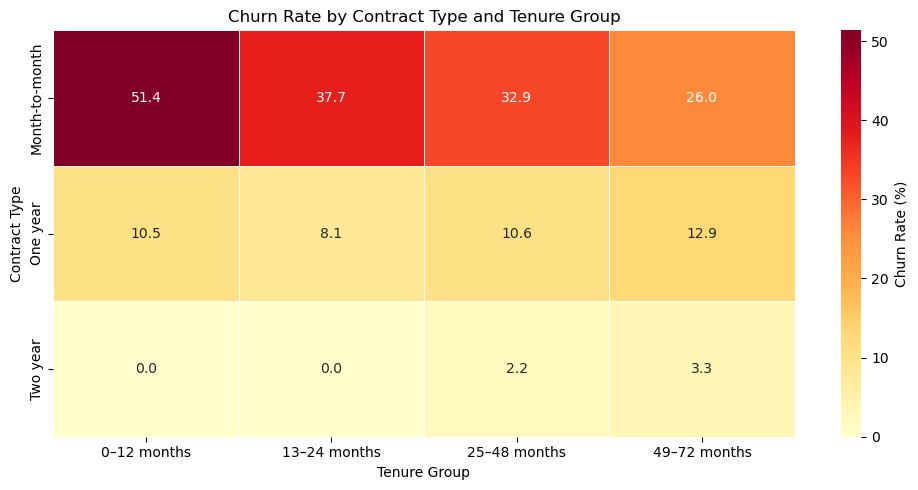

In [178]:
#heatmap of churn rates by contract and tenure groups
import seaborn as sns
import matplotlib.pyplot as plt

churn_heatmap = (
    df.groupby(["Contract", "TenureGroup"], observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .unstack()
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    churn_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"}
)

plt.title("Churn Rate by Contract Type and Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Contract Type")
plt.tight_layout()
plt.savefig(r"images\churn_by_contract_type_and_tenure.png",
            dpi=300, bbox_inches="tight")
plt.show()

the heatmap reveals substantial differences in churn rates across contract types and tenure groups. Month-to-month customers exhibit the highest churn rates, particularly during their first 12 months, when the observed churn rate reaches 51.4%. Churn declines with tenure among month-to-month customers but remains considerably higher than for customers with longer-term contracts. One-year and two-year contracts are associated with much lower observed churn rates. However, the zero churn rates in the two shortest-tenure groups for two-year contracts should be interpreted cautiously because their sample sizes are relatively small. These findings suggest that contract type and tenure are important variables to investigate when understanding customer churn.

Conclusion

This project explored customer churn using exploratory data analysis and machine learning. After cleaning the dataset and examining customer characteristics, I trained and compared Logistic Regression, Decision Tree, and Random Forest models.

Logistic Regression achieved a ROC-AUC of approximately 0.842 and was selected for its combination of predictive performance and interpretability.

Instead of relying exclusively on the default classification threshold of 0.50, I evaluated alternative thresholds and selected 0.35 to prioritize identifying customers at risk of churning. At this threshold, the model achieved a recall of approximately 70.6% on the held-out test set, with precision of 54.3%.

Feature analysis highlighted tenure, internet service type, and contract type as important predictors of churn. The exploratory analysis also showed higher observed churn rates among month-to-month customers and customers with shorter tenure.

Overall, this project demonstrates how exploratory data analysis, model evaluation, threshold selection, and feature interpretation can support data-driven customer retention strategies. The identified relationships are predictive associations and should not be interpreted as evidence of causation.